In [62]:
from IPython.display import HTML, display
COMPACT_PRINT_CSS = "<style>\n@page { size: A4 portrait; margin: 11mm 12mm 12mm 12mm; }\n@media print {\n  :root { --jp-content-font-family: Arial, sans-serif; }\n  body { background: white !important; }\n  html, body { margin: 0 !important; padding: 0 !important; width: auto !important; }\n  body, .jp-RenderedHTMLCommon { font-family: Arial, sans-serif !important;\n    font-size: 9.6pt !important; line-height: 1.23 !important; color: #111 !important; }\n  .jp-Notebook { padding: 0 !important; margin: 0 !important; width: auto !important;\n    max-width: none !important; min-width: 0 !important; }\n  main, .jp-Cell, .jp-Cell-inputWrapper, .jp-Cell-outputWrapper,\n  .jp-InputArea, .jp-OutputArea, .jp-OutputArea-child, .jp-InputArea-editor,\n  .jp-RenderedHTMLCommon, .jp-RenderedText { min-width: 0 !important;\n    max-width: 100% !important; }\n  .jp-Cell { padding: 0 !important; margin: 0 0 4pt !important;\n    break-inside: auto !important; }\n  .jp-Cell-inputWrapper, .jp-Cell-outputWrapper { margin: 0 !important;\n    padding: 0 !important; }\n  .jp-InputPrompt, .jp-OutputPrompt, .jp-Collapser { display: none !important; }\n  .jp-RenderedMarkdown { padding: 0 !important; }\n  .jp-RenderedMarkdown h1 { font-size: 15pt !important; line-height: 1.14 !important;\n    margin: 0 0 6pt !important; break-after: avoid !important; }\n  .jp-RenderedMarkdown h2 { font-size: 12pt !important; line-height: 1.18 !important;\n    margin: 8pt 0 4pt !important; break-after: avoid !important; }\n  .jp-RenderedMarkdown p { margin: 3pt 0 5pt !important; orphans: 3; widows: 3; }\n  .jp-RenderedMarkdown a { color: #155d8b !important; text-decoration: none; }\n  .jp-InputArea-editor { border: 0.4pt solid #d7dce2 !important;\n    background: #f6f7f9 !important; border-radius: 0 !important; padding: 0 !important; }\n  .highlight { padding: 0 !important; margin: 0 !important; background: transparent !important; }\n  .highlight pre { font-family: 'DejaVu Sans Mono', Consolas, monospace !important;\n    font-size: 8.2pt !important; line-height: 1.17 !important; padding: 5pt 6pt !important;\n    margin: 0 !important; white-space: pre-wrap !important; overflow-wrap: anywhere !important;\n    word-break: normal !important; tab-size: 4; }\n  pre, code, .cm-editor, .jp-InputArea-editor { overflow: visible !important;\n    text-overflow: clip !important; max-height: none !important; }\n  .jp-RenderedText pre { font-family: 'DejaVu Sans Mono', Consolas, monospace !important;\n    font-size: 8.1pt !important; line-height: 1.2 !important; padding: 2pt 0 !important;\n    margin: 0 !important; white-space: pre-wrap !important; overflow-wrap: anywhere !important; }\n  .jp-RenderedImage { padding: 2pt 0 !important; text-align: center !important;\n    break-inside: avoid !important; }\n  .jp-RenderedImage img { display: block !important; width: 100% !important;\n    max-width: 100% !important; height: auto !important; margin: 0 auto !important;\n    break-inside: avoid !important; }\n  .jp-OutputArea-child { padding: 0 !important; break-inside: avoid !important; }\n .celltag_hide-input > .jp-Cell-inputWrapper { display: none !important; }\n  .anchor-link { display: none !important; }\n  mjx-container { font-size: 100% !important; }\n}\n</style>"
display(HTML(COMPACT_PRINT_CSS))

$\LARGE{EN3160\ Assignment\ 3}\\\LARGE{Neural\ Networks}$

$\large{Index:\ 230544C}\\
\large{Name:\ Rathnayake\ M.\ A.\ G.\ K.\ N.}$

[GitHub folder](https://github.com/codingNR29/Image-processing/tree/main/Assignments/Assignment%203)

[GitHub repo](https://github.com/codingNR29/Image-processing.git)

In [48]:
#Adding libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import models
import torchvision.transforms as transforms
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from pathlib import Path

$Q1)$

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/20, Loss: 0.9769858931303024
Epoch 2/20, Loss: 0.9498391682505608
Epoch 3/20, Loss: 0.9360962734222412
Epoch 4/20, Loss: 0.9275455605387688
Epoch 5/20, Loss: 0.9216074377298356
Epoch 6/20, Loss: 0.9172044582366944
Epoch 7/20, Loss: 0.9137922565340996
Epoch 8/20, Loss: 0.9110655336380005
Epoch 9/20, Loss: 0.9088373825550079
Epoch 10/20, Loss: 0.9069848419427872
Epoch 11/20, Loss: 0.905424839913845
Epoch 12/20, Loss: 0.9040972554087638
Epoch 13/20, Loss: 0.9029587873220444
Epoch 14/20, Loss: 0.9019751689434051
Epoch 15/20, Loss: 0.9011213612556458
Epoch 16/20, Loss: 0.900376247882843
Epoch 17/20, Loss: 0.8997236246466637
Epoch 18/20, Loss: 0.8991501525640487
Epoch 19/20, Loss: 0.8986445634365082
Epoch 20/20, Loss: 0.8981979598402977


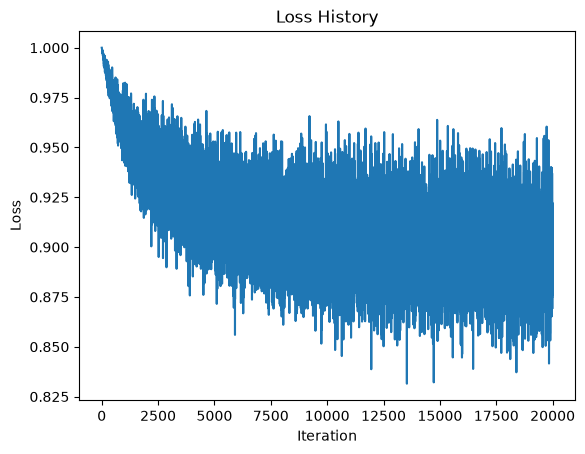

Training accuracy: 32.19%
Test accuracy: 32.38%


In [6]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=2
)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = torch.randn(Din, K) * std  # One layer: directly map input to output
b = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 2e-6          # Learning rate
lr_decay = 0.9     # Learning rate decay
reg = 0            # Regularization
loss_history = []


# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                                      # Batch size
        x_train = inputs.view(Ntr, -1)                             # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot

        # Forward pass
        y_pred = x_train.mm(w) + b                                 # Output layer activation

        # Loss calculation (Mean Squared Error with regularization)
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay


# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")


# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

$a)$

In [7]:
#Selecting device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

torch.manual_seed(42)

#New network parameters
Din = 3 * 32 * 32
H = 100
K = 10

#Defining layer weights

#Layer 1
W1 = torch.randn(Din, H, device=device) / (Din ** 0.5)
b1 = torch.zeros(H, device=device)

#Layer 2
W2 = torch.randn(H, K, device=device) / (H ** 0.5)
b2 = torch.zeros(K, device=device)

lr = 0.1
epochs = 10

epoch_losses = []


Using: cuda


$b)$

In [8]:
#Training
for epoch in range(epochs):
    total_loss = 0.0
    total_samples = 0

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        N = images.shape[0]
        X = images.reshape(N, -1)

        # Forward propagation
        Z1 = X @ W1 + b1
        A1 = torch.sigmoid(Z1)
        Z2 = A1 @ W2 + b2

        # Stable softmax and cross-entropy
        log_probs = Z2 - torch.logsumexp(
            Z2, dim=1, keepdim=True
        )
        loss = -log_probs[
            torch.arange(N, device=device), labels
        ].mean()

        # Manual backward propagation
        dZ2 = torch.exp(log_probs) #Converting log probabilities into probabilities
        dZ2[torch.arange(N, device=device), labels] -= 1 #Substracting 1 from the correct class probability
        dZ2 /= N #Dividing by batch size

        dW2 = A1.T @ dZ2 
        db2 = dZ2.sum(dim=0)

        dZ1 = (dZ2 @ W2.T) * A1 * (1 - A1)

        dW1 = X.T @ dZ1
        db1 = dZ1.sum(dim=0)

        # Gradient descent
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

        total_loss += loss.item() * N
        total_samples += N

    avg_loss = total_loss / total_samples
    epoch_losses.append(avg_loss)

    print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")


Epoch 1/10 | Loss: 1.8062
Epoch 2/10 | Loss: 1.6788
Epoch 3/10 | Loss: 1.6180
Epoch 4/10 | Loss: 1.5704
Epoch 5/10 | Loss: 1.5255
Epoch 6/10 | Loss: 1.4839
Epoch 7/10 | Loss: 1.4487
Epoch 8/10 | Loss: 1.4144
Epoch 9/10 | Loss: 1.3819
Epoch 10/10 | Loss: 1.3534


$c)$

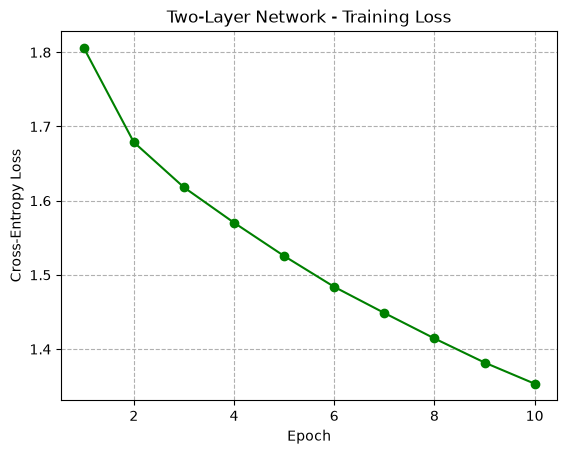

Training accuracy: 55.58%
Test accuracy: 48.04%


In [9]:
#Visualization
plt.plot(range(1, epochs + 1), epoch_losses,color = 'green', marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Two-Layer Network - Training Loss")
plt.grid(True, linestyle = "--")
plt.show()

def calculate_accuracy(loader):
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            X = images.to(device).reshape(images.shape[0], -1)
            labels = labels.to(device)

            A1 = torch.sigmoid(X @ W1 + b1)
            logits = A1 @ W2 + b2

            predicted = torch.argmax(logits, dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

train_acc = calculate_accuracy(trainloader)
test_acc = calculate_accuracy(testloader)

print(f"Training accuracy: {train_acc:.2f}%")
print(f"Test accuracy: {test_acc:.2f}%")


### Q1: Results and Discussion

A two-layer fully connected neural network was implemented for CIFAR-10 image classification by extending the provided single-layer network. A hidden layer consisting of 100 neurons with sigmoid activation was introduced, and the original mean squared error objective was replaced with softmax cross-entropy loss. Forward propagation and backpropagation were implemented manually using matrix operations and the chain rule.

The network was trained for 10 epochs using mini-batch gradient descent. The training loss decreased consistently from approximately 1.81 to 1.35, indicating that the network was successfully learning from the training data.

The final training accuracy was **55.58%**, while the test accuracy was **48.04%**. The difference of 7.54 percentage points suggests a generalization gap between training and unseen data. Although the network performed substantially better than random classification, its performance was limited by the use of flattened pixel values rather than spatial feature extraction.

The experiment demonstrates how nonlinear activations, cross-entropy loss, and backpropagation enable a multilayer network to learn image classification. It also motivates the use of convolutional neural networks, which can better exploit spatial relationships within images.

$Q2)$

Using device: cuda
Image batch shape: torch.Size([64, 1, 32, 32])
Label batch shape: torch.Size([64])


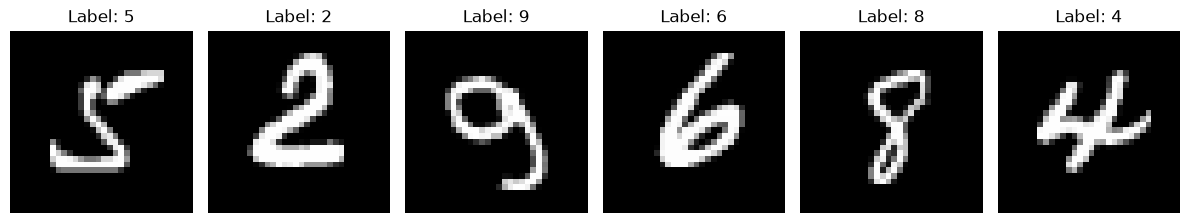

In [18]:
#Data loading and visualization
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

#Prepare the images
mnist_transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

#Download/load MNIST
mnist_trainset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=mnist_transform
)

mnist_testset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=mnist_transform
)

#Create DataLoaders
batch_size = 64

mnist_trainloader = DataLoader(
    mnist_trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

mnist_testloader = DataLoader(
    mnist_testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

#Examine one batch
images, labels = next(iter(mnist_trainloader))

print("Image batch shape:", images.shape) #Batch, channels, height, width
print("Label batch shape:", labels.shape)

#Display the first six images
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    img = images[i, 0] * 0.5 + 0.5
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

$a)$

In [19]:
#Creating the neural network
class LeNet5(nn.Module):
    
    def __init__(self):
        super().__init__()

        #First convolution: 1 -> 6 channels
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=6,
            kernel_size=5
        )

        #Second convolution: 6 -> 16 channels
        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )

        #Pooling and activation
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.activation = nn.Tanh()

        #Fully connected layers
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):

        #Convolution block 1
        x = self.conv1(x)
        x = self.activation(x)
        x = self.pool(x)

        #Convolution block 2
        x = self.conv2(x)
        x = self.activation(x)
        x = self.pool(x)

        #Convert feature maps into a vector
        x = torch.flatten(x, start_dim=1)

        #Fully connected classifier
        x = self.activation(self.fc1(x))
        x = self.activation(self.fc2(x))
        x = self.fc3(x)

        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

lenet_model = LeNet5().to(device)

print(lenet_model)
print("Total parameters:",
      sum(p.numel() for p in lenet_model.parameters()))

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (activation): Tanh()
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Total parameters: 61706


In [20]:
#Checking the dimensions
images, labels = next(iter(mnist_trainloader))

x = images.to(device)

with torch.no_grad():
    print("Input: ", x.shape)

    x = lenet_model.conv1(x)
    print("Conv 1:", x.shape)

    x = lenet_model.pool(lenet_model.activation(x))
    print("Pool 1:", x.shape)

    x = lenet_model.conv2(x)
    print("Conv 2:", x.shape)

    x = lenet_model.pool(lenet_model.activation(x))
    print("Pool 2:", x.shape)

    x = torch.flatten(x, start_dim=1)
    print("Flatten:", x.shape)

    x = lenet_model.fc1(x)
    print("FC 1:", x.shape)

Input:  torch.Size([64, 1, 32, 32])
Conv 1: torch.Size([64, 6, 28, 28])
Pool 1: torch.Size([64, 6, 14, 14])
Conv 2: torch.Size([64, 16, 10, 10])
Pool 2: torch.Size([64, 16, 5, 5])
Flatten: torch.Size([64, 400])
FC 1: torch.Size([64, 120])


In [21]:
#Define the loss function
criterion = nn.CrossEntropyLoss()

#Define the optimizer
optimizer = torch.optim.Adam(
    lenet_model.parameters(),
    lr=0.001
)

#Store results for plotting later
lenet_history = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

In [22]:
#Training and evaluation
epochs = 10

for epoch in range(epochs):

    #Training
    lenet_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in mnist_trainloader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = lenet_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size

        predicted = outputs.argmax(dim=1)

        train_correct += (predicted == labels).sum().item()
        train_total += batch_size

    #Testing
    lenet_model.eval()

    test_loss_sum = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for images, labels in mnist_testloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = lenet_model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            test_loss_sum += loss.item() * batch_size

            predicted = outputs.argmax(dim=1)

            test_correct += (predicted == labels).sum().item()
            test_total += batch_size

    #Calculate epoch averages
    train_loss = train_loss_sum / train_total
    test_loss = test_loss_sum / test_total

    train_acc = 100 * train_correct / train_total
    test_acc = 100 * test_correct / test_total

    #Save results
    lenet_history["train_loss"].append(train_loss)
    lenet_history["train_acc"].append(train_acc)
    lenet_history["test_loss"].append(test_loss)
    lenet_history["test_acc"].append(test_acc)

    #Display results
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )


Epoch 1/10 | Train Loss: 0.2834 | Train Acc: 91.59% | Test Loss: 0.1077 | Test Acc: 96.72%
Epoch 2/10 | Train Loss: 0.0911 | Train Acc: 97.23% | Test Loss: 0.0763 | Test Acc: 97.64%
Epoch 3/10 | Train Loss: 0.0636 | Train Acc: 97.97% | Test Loss: 0.0635 | Test Acc: 98.10%
Epoch 4/10 | Train Loss: 0.0473 | Train Acc: 98.55% | Test Loss: 0.0554 | Test Acc: 98.23%
Epoch 5/10 | Train Loss: 0.0392 | Train Acc: 98.73% | Test Loss: 0.0471 | Test Acc: 98.47%
Epoch 6/10 | Train Loss: 0.0326 | Train Acc: 98.96% | Test Loss: 0.0476 | Test Acc: 98.37%
Epoch 7/10 | Train Loss: 0.0269 | Train Acc: 99.15% | Test Loss: 0.0465 | Test Acc: 98.51%
Epoch 8/10 | Train Loss: 0.0226 | Train Acc: 99.27% | Test Loss: 0.0563 | Test Acc: 98.32%
Epoch 9/10 | Train Loss: 0.0198 | Train Acc: 99.36% | Test Loss: 0.0505 | Test Acc: 98.55%
Epoch 10/10 | Train Loss: 0.0181 | Train Acc: 99.41% | Test Loss: 0.0492 | Test Acc: 98.56%


$b)$

In [23]:
#Defining new model
class ModernCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            #Convolution block 1
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            #Convolution block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            #Convolution block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(p=0.2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


modern_model = ModernCNN().to(device)

print(modern_model)

print("Total parameters:",
      sum(p.numel() for p in modern_model.parameters()))

ModernCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Dropout2d(p=0.2, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bi

In [24]:
#Checking the architecture
images, labels = next(iter(mnist_trainloader))

x = images.to(device)

modern_model.eval()

with torch.no_grad():

    print("Input:", x.shape)

    features = modern_model.features(x)
    print("After convolution blocks:", features.shape)

    flattened = torch.flatten(features, start_dim=1)
    print("After flatten:", flattened.shape)

    outputs = modern_model(x)
    print("Final output:", outputs.shape)


Input: torch.Size([64, 1, 32, 32])
After convolution blocks: torch.Size([64, 64, 4, 4])
After flatten: torch.Size([64, 1024])
Final output: torch.Size([64, 10])


In [ ]:
#Define the optimizer
modern_optimizer = torch.optim.Adam(
    modern_model.parameters(),
    lr=0.001
)

#Store results for plotting later
modern_model_history = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

train_loss 0
train_acc 0
test_loss 0
test_acc 0


In [34]:
#Training and evaluation of the modern model
epochs = 10

for epoch in range(epochs):     

    #Training
    modern_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in mnist_trainloader:

        images = images.to(device)
        labels = labels.to(device)

        modern_optimizer.zero_grad()

        outputs = modern_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        modern_optimizer.step()

        current_batch_size = labels.size(0)

        train_loss_sum += loss.item() * current_batch_size

        predicted = outputs.argmax(dim=1)

        train_correct += (predicted == labels).sum().item()
        train_total += current_batch_size

    #Testing
    modern_model.eval()

    test_loss_sum = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for images, labels in mnist_testloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = modern_model(images)
            loss = criterion(outputs, labels)

            current_batch_size = labels.size(0)

            test_loss_sum += loss.item() * current_batch_size

            predicted = outputs.argmax(dim=1)

            test_correct += (predicted == labels).sum().item()
            test_total += current_batch_size

    #Calculate epoch averages
    train_loss = train_loss_sum / train_total
    test_loss = test_loss_sum / test_total

    train_acc = 100 * train_correct / train_total
    test_acc = 100 * test_correct / test_total

    #Save results
    modern_model_history["train_loss"].append(train_loss)
    modern_model_history["train_acc"].append(train_acc)
    modern_model_history["test_loss"].append(test_loss)
    modern_model_history["test_acc"].append(test_acc)

    #Display results
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )


Epoch 1/10 | Train Loss: 0.0198 | Train Acc: 99.39% | Test Loss: 0.0196 | Test Acc: 99.41%
Epoch 2/10 | Train Loss: 0.0171 | Train Acc: 99.48% | Test Loss: 0.0256 | Test Acc: 99.29%
Epoch 3/10 | Train Loss: 0.0179 | Train Acc: 99.44% | Test Loss: 0.0221 | Test Acc: 99.33%
Epoch 4/10 | Train Loss: 0.0161 | Train Acc: 99.50% | Test Loss: 0.0231 | Test Acc: 99.28%
Epoch 5/10 | Train Loss: 0.0151 | Train Acc: 99.51% | Test Loss: 0.0226 | Test Acc: 99.37%
Epoch 6/10 | Train Loss: 0.0153 | Train Acc: 99.49% | Test Loss: 0.0246 | Test Acc: 99.50%
Epoch 7/10 | Train Loss: 0.0153 | Train Acc: 99.51% | Test Loss: 0.0249 | Test Acc: 99.34%
Epoch 8/10 | Train Loss: 0.0145 | Train Acc: 99.56% | Test Loss: 0.0263 | Test Acc: 99.43%
Epoch 9/10 | Train Loss: 0.0134 | Train Acc: 99.60% | Test Loss: 0.0254 | Test Acc: 99.32%
Epoch 10/10 | Train Loss: 0.0145 | Train Acc: 99.57% | Test Loss: 0.0246 | Test Acc: 99.41%


$c)$

In [35]:
#Checking the training histories
for model_name, history in [
    ("LeNet-5", lenet_history),
    ("Modern CNN", modern_model_history)
]:
    print(f"\n{model_name}")

    for key, values in history.items():
        print(f"{key}: {len(values)} epochs")

    assert all(len(values) == 10 for values in history.values()), \
        f"{model_name}: Expected 10 epochs of results"

    assert all(
        0 <= acc <= 100
        for key in ["train_acc", "test_acc"]
        for acc in history[key]
    ), f"{model_name}: Invalid accuracy found"



LeNet-5
train_loss: 10 epochs
train_acc: 10 epochs
test_loss: 10 epochs
test_acc: 10 epochs

Modern CNN
train_loss: 10 epochs
train_acc: 10 epochs
test_loss: 10 epochs
test_acc: 10 epochs


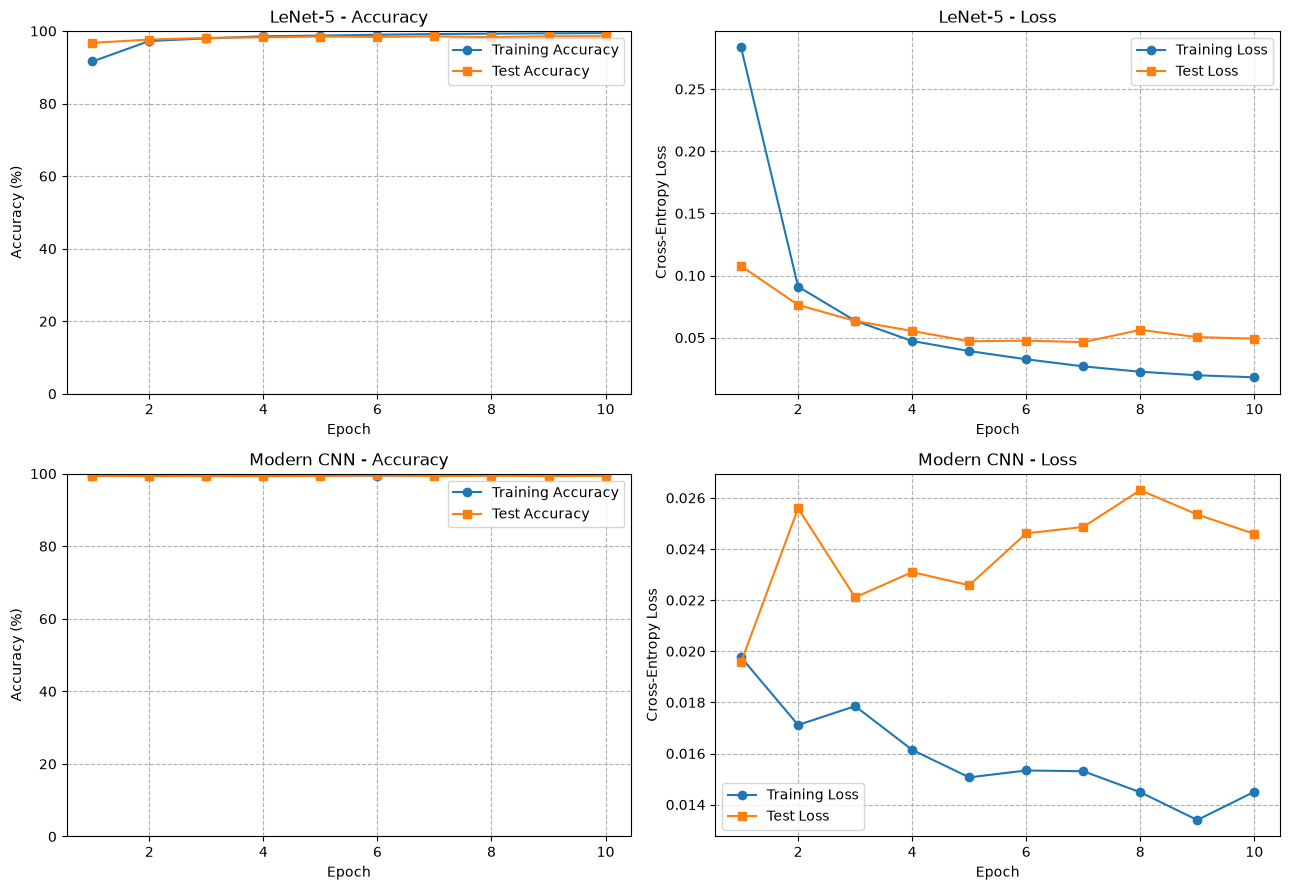

In [38]:
#Plotting accuracy and loss for both models
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

histories = [
    ("LeNet-5", lenet_history),
    ("Modern CNN", modern_model_history)
]

for row, (model_name, history) in enumerate(histories):

    epochs_range = range(1, len(history["train_acc"]) + 1)

    #Accuracy
    axes[row, 0].plot(
        epochs_range,
        history["train_acc"],
        marker="o",
        label="Training Accuracy"
    )

    axes[row, 0].plot(
        epochs_range,
        history["test_acc"],
        marker="s",
        label="Test Accuracy"
    )

    axes[row, 0].set_title(f"{model_name} - Accuracy")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Accuracy (%)")
    axes[row, 0].set_ylim(0, 100)
    axes[row, 0].legend()
    axes[row, 0].grid(True, linestyle ="--")

    #Loss
    axes[row, 1].plot(
        epochs_range,
        history["train_loss"],
        marker="o",
        label="Training Loss"
    )

    axes[row, 1].plot(
        epochs_range,
        history["test_loss"],
        marker="s",
        label="Test Loss"
    )

    axes[row, 1].set_title(f"{model_name} - Loss")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("Cross-Entropy Loss")
    axes[row, 1].legend()
    axes[row, 1].grid(True, linestyle ="--")

plt.tight_layout()
plt.show()


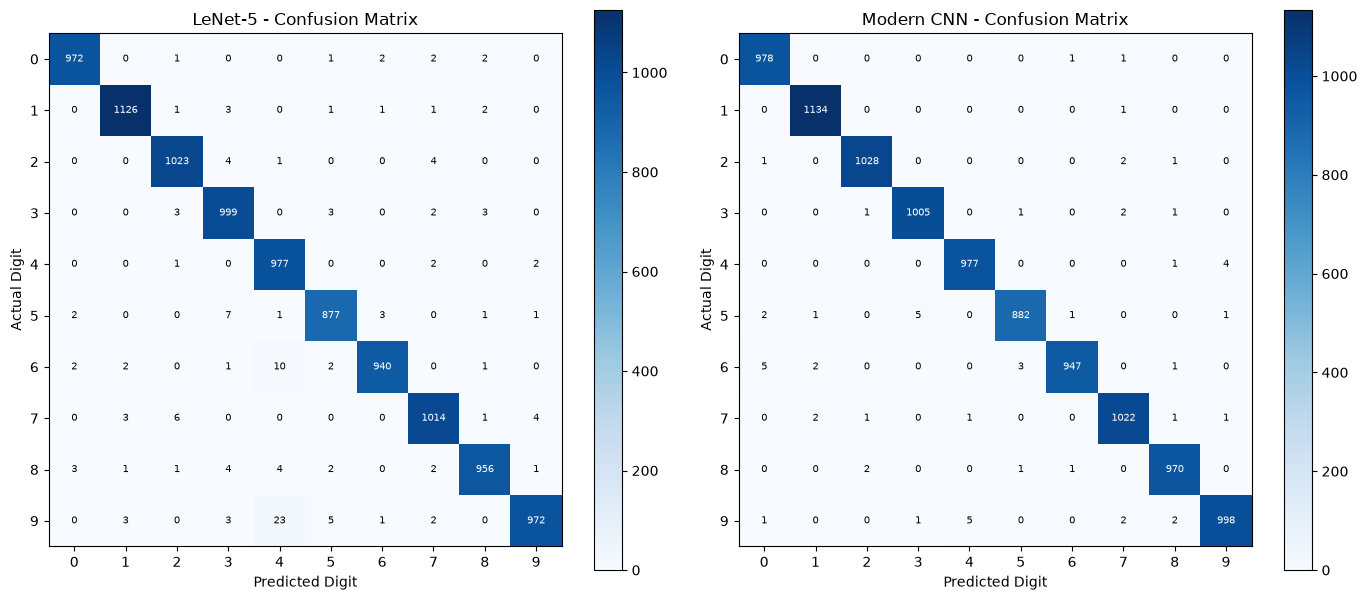

LeNet-5 Test Accuracy: 98.56%
Modern CNN Test Accuracy: 99.41%


In [39]:
#Computing the confusion matrices
def get_confusion_matrix(model, loader):

    matrix = torch.zeros(10, 10, dtype=torch.int64)

    model.eval()

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predicted = outputs.argmax(dim=1)

            for actual, prediction in zip(labels, predicted):
                matrix[actual.item(), prediction.item()] += 1

    return matrix.numpy()


lenet_cm = get_confusion_matrix(lenet_model, mnist_testloader)
modern_cm = get_confusion_matrix(modern_model, mnist_testloader)


#Displaying both confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

matrices = [
    ("LeNet-5", lenet_cm),
    ("Modern CNN", modern_cm)
]

for ax, (name, cm) in zip(axes, matrices):

    im = ax.imshow(cm, cmap="Blues")

    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted Digit")
    ax.set_ylabel("Actual Digit")

    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    for i in range(10):
        for j in range(10):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )

    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

print("LeNet-5 Test Accuracy:",
      f"{100 * lenet_cm.diagonal().sum() / lenet_cm.sum():.2f}%")

print("Modern CNN Test Accuracy:",
      f"{100 * modern_cm.diagonal().sum() / modern_cm.sum():.2f}%")


### Q2 : Discussion

Two CNN models were implemented using the MNIST dataset: LeNet-5 with average pooling and Tanh activation, and a modern 3-layer CNN with ReLU, batch normalization, max pooling, and dropout.

Both models were trained for 10 epochs using cross-entropy loss and the Adam optimizer. Training and test accuracy, loss curves, and confusion matrices were used to evaluate and compare their performance.

$Q3)$

In [44]:
#Defining the transformations
data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

#Defining the dataset location
data_dir = Path(
    r"F:\Image processing\Assignments\Assignment 3\data\hymenoptera_data"
)

#Loading the datasets
image_datasets = {
    phase: datasets.ImageFolder(
        root=str(data_dir / phase),
        transform=data_transforms[phase]
    )
    for phase in ["train", "val"]
}

#Creating the DataLoaders
dataloaders = {
    phase: DataLoader(
        image_datasets[phase],
        batch_size=4,
        shuffle=(phase == "train"),
        num_workers=0
    )
    for phase in ["train", "val"]
}

class_names = image_datasets["train"].classes

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Classes:", class_names)
print("Training images:", len(image_datasets["train"]))
print("Validation images:", len(image_datasets["val"]))
print("Device:", device)

Classes: ['ants', 'bees']
Training images: 244
Validation images: 153
Device: cuda


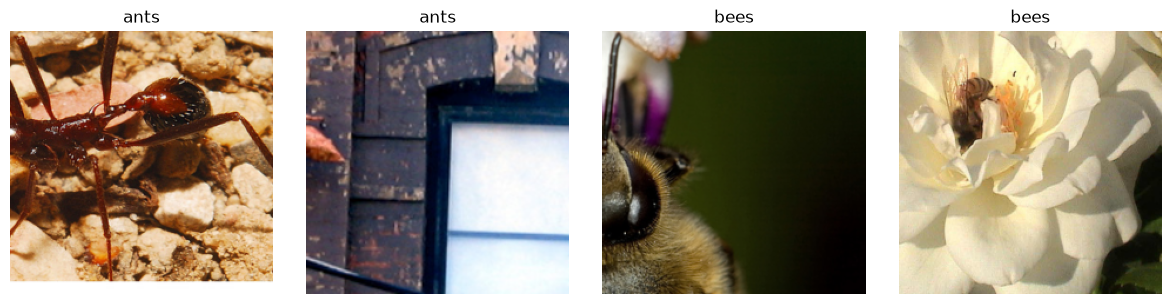

In [47]:
#Visualizing the training images
images, labels = next(iter(dataloaders["train"]))

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i in range(4):
    image = images[i].permute(1, 2, 0)

    image = image * torch.tensor(
        [0.229, 0.224, 0.225]
    ) + torch.tensor(
        [0.485, 0.456, 0.406]
    )

    image = image.clamp(0, 1)

    axes[i].imshow(image)
    axes[i].set_title(class_names[labels[i].item()])
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [49]:
#Loading pretrained ResNet18
weights = models.ResNet18_Weights.IMAGENET1K_V1

resnet_finetune = models.resnet18(weights=weights)

#Replacing the final fully connected layer
num_features = resnet_finetune.fc.in_features

resnet_finetune.fc = nn.Linear(num_features, 2)

#Moving the model to GPU or CPU
resnet_finetune = resnet_finetune.to(device)

print("Original final layer inputs:", num_features)
print("New final layer:", resnet_finetune.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:13<00:00, 3.51MB/s]


Original final layer inputs: 512
New final layer: Linear(in_features=512, out_features=2, bias=True)


In [50]:
#Checking the ResNet18 model
images, labels = next(iter(dataloaders["train"]))

images = images.to(device)

resnet_finetune.eval()

with torch.no_grad():
    outputs = resnet_finetune(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in resnet_finetune.parameters()
        if p.requires_grad
    )
)

Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 2])
Trainable parameters: 11177538


$a)$ 

In [51]:
#Defining the loss function
resnet_criterion = nn.CrossEntropyLoss()

#Defining the optimizer
finetune_optimizer = torch.optim.SGD(
    resnet_finetune.parameters(),
    lr=0.001,
    momentum=0.9
)

#Storing training results
finetune_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

In [52]:
#Training and evaluating ResNet18
epochs = 5

for epoch in range(epochs):

    #Training
    resnet_finetune.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in dataloaders["train"]:

        images = images.to(device)
        labels = labels.to(device)

        finetune_optimizer.zero_grad()

        outputs = resnet_finetune(images)
        loss = resnet_criterion(outputs, labels)

        loss.backward()
        finetune_optimizer.step()

        current_batch_size = labels.size(0)

        train_loss_sum += loss.item() * current_batch_size

        predicted = outputs.argmax(dim=1)

        train_correct += (predicted == labels).sum().item()
        train_total += current_batch_size

    #Validation
    resnet_finetune.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in dataloaders["val"]:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_finetune(images)
            loss = resnet_criterion(outputs, labels)

            current_batch_size = labels.size(0)

            val_loss_sum += loss.item() * current_batch_size

            predicted = outputs.argmax(dim=1)

            val_correct += (predicted == labels).sum().item()
            val_total += current_batch_size

    #Calculating epoch averages
    train_loss = train_loss_sum / train_total
    train_acc = 100 * train_correct / train_total

    val_loss = val_loss_sum / val_total
    val_acc = 100 * val_correct / val_total

    #Saving results
    finetune_history["train_loss"].append(train_loss)
    finetune_history["train_acc"].append(train_acc)
    finetune_history["val_loss"].append(val_loss)
    finetune_history["val_acc"].append(val_acc)

    #Displaying results
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 1/5 | Train Loss: 0.5533 | Train Acc: 72.13% | Val Loss: 0.3129 | Val Acc: 89.54%
Epoch 2/5 | Train Loss: 0.5936 | Train Acc: 72.95% | Val Loss: 0.2022 | Val Acc: 94.77%
Epoch 3/5 | Train Loss: 0.5327 | Train Acc: 73.36% | Val Loss: 0.2715 | Val Acc: 90.85%
Epoch 4/5 | Train Loss: 0.4928 | Train Acc: 80.74% | Val Loss: 0.3336 | Val Acc: 89.54%
Epoch 5/5 | Train Loss: 0.4600 | Train Acc: 83.20% | Val Loss: 0.4203 | Val Acc: 85.62%


In [54]:
#Displaying fine-tuning results
print("Final Training Accuracy:",
      f"{finetune_history['train_acc'][-1]:.2f}%")

print("Final Validation Accuracy:",
      f"{finetune_history['val_acc'][-1]:.2f}%")

print("Best Validation Accuracy:",
      f"{max(finetune_history['val_acc']):.2f}%")

Final Training Accuracy: 83.20%
Final Validation Accuracy: 85.62%
Best Validation Accuracy: 94.77%


$b)$

In [55]:
#Loading a fresh pretrained ResNet18
resnet_feature = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

#Freezing the pretrained parameters
for param in resnet_feature.parameters():
    param.requires_grad = False

#Replacing the final classification layer
num_features = resnet_feature.fc.in_features
resnet_feature.fc = nn.Linear(num_features, 2)

#Moving the model to the device
resnet_feature = resnet_feature.to(device)

#Checking the trainable parameters
print("Final layer:", resnet_feature.fc)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in resnet_feature.parameters()
        if p.requires_grad
    )
)

Final layer: Linear(in_features=512, out_features=2, bias=True)
Trainable parameters: 1026


In [56]:
#Defining the loss function
feature_criterion = nn.CrossEntropyLoss()

#Defining the optimizer
feature_optimizer = torch.optim.SGD(
    resnet_feature.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

#Storing training results
feature_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

In [57]:
#Training and evaluation of the feature extraction model
epochs = 5

for epoch in range(epochs):

    #Training
    resnet_feature.eval()
    resnet_feature.fc.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in dataloaders["train"]:

        images = images.to(device)
        labels = labels.to(device)

        feature_optimizer.zero_grad()

        outputs = resnet_feature(images)

        loss = feature_criterion(outputs, labels)

        loss.backward()

        feature_optimizer.step()

        current_batch_size = labels.size(0)

        train_loss_sum += loss.item() * current_batch_size

        predicted = outputs.argmax(dim=1)

        train_correct += (predicted == labels).sum().item()
        train_total += current_batch_size

    #Validation
    resnet_feature.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in dataloaders["val"]:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_feature(images)

            loss = feature_criterion(outputs, labels)

            current_batch_size = labels.size(0)

            val_loss_sum += loss.item() * current_batch_size

            predicted = outputs.argmax(dim=1)

            val_correct += (predicted == labels).sum().item()
            val_total += current_batch_size

    #Calculate epoch averages
    train_loss = train_loss_sum / train_total
    val_loss = val_loss_sum / val_total

    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    #Save results
    feature_history["train_loss"].append(train_loss)
    feature_history["train_acc"].append(train_acc)
    feature_history["val_loss"].append(val_loss)
    feature_history["val_acc"].append(val_acc)

    #Display results
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 1/5 | Train Loss: 0.3600 | Train Acc: 82.38% | Val Loss: 0.1931 | Val Acc: 94.12%
Epoch 2/5 | Train Loss: 0.1578 | Train Acc: 93.85% | Val Loss: 0.1490 | Val Acc: 95.42%
Epoch 3/5 | Train Loss: 0.1259 | Train Acc: 94.26% | Val Loss: 0.1678 | Val Acc: 94.77%
Epoch 4/5 | Train Loss: 0.1776 | Train Acc: 92.21% | Val Loss: 0.1487 | Val Acc: 96.08%
Epoch 5/5 | Train Loss: 0.1261 | Train Acc: 95.49% | Val Loss: 0.1651 | Val Acc: 94.77%


In [58]:
#Displaying the feature extraction results
print("Final Training Accuracy:",
      f"{feature_history['train_acc'][-1]:.2f}%")

print("Final Validation Accuracy:",
      f"{feature_history['val_acc'][-1]:.2f}%")

print("Best Validation Accuracy:",
      f"{max(feature_history['val_acc']):.2f}%")


Final Training Accuracy: 95.49%
Final Validation Accuracy: 94.77%
Best Validation Accuracy: 96.08%


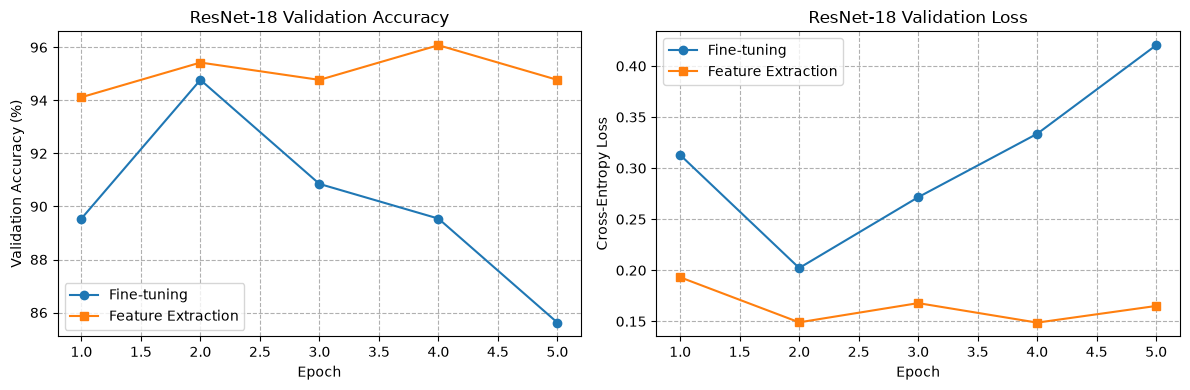

In [61]:
#Comparing fine-tuning and feature extraction
epochs_fine = range(1, len(finetune_history["val_acc"]) + 1)
epochs_feature = range(1, len(feature_history["val_acc"]) + 1)

plt.figure(figsize=(12, 4))

#Comparing validation accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_fine,
    finetune_history["val_acc"],
    marker="o",
    label="Fine-tuning"
)

plt.plot(
    epochs_feature,
    feature_history["val_acc"],
    marker="s",
    label="Feature Extraction"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("ResNet-18 Validation Accuracy")
plt.legend()
plt.grid(True, linestyle = "--")

#Comparing validation loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_fine,
    finetune_history["val_loss"],
    marker="o",
    label="Fine-tuning"
)

plt.plot(
    epochs_feature,
    feature_history["val_loss"],
    marker="s",
    label="Feature Extraction"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("ResNet-18 Validation Loss")
plt.legend()
plt.grid(True, linestyle = "--")

plt.tight_layout()
plt.show()

### Q3 : Discussion

A pretrained ResNet-18 model was used to classify ants and bees using two transfer-learning approaches: fine-tuning all layers and freezing the pretrained layers while training only the final classifier.

After five epochs, fine-tuning achieved 85.62% final validation accuracy (best: 94.77%), while feature extraction achieved 94.77% final validation accuracy (best: 96.08%).

Feature extraction performed better in this experiment, suggesting that the pretrained ImageNet features were effective for this small dataset. Fine-tuning showed greater fluctuations in validation performance, potentially due to the limited training data.